In [1]:
import pandas as pd
import numpy as np

In [2]:
import keras

In [3]:
ab = pd.read_csv("Alphabets_data.csv")

In [4]:
ab

,letter,xbox,ybox,width,height,onpix,xbar,ybar,x2bar,y2bar,xybar,x2ybar,xy2bar,xedge,xedgey,yedge,yedgex
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,D,2,2,3,3,2,7,7,7,6,6,6,4,2,8,3,7
19996,C,7,10,8,8,4,4,8,6,9,12,9,13,2,9,3,7
19997,T,6,9,6,7,5,6,11,3,7,11,9,5,2,12,2,4
19998,S,2,3,4,2,1,8,7,2,6,10,6,8,1,9,5,8


In [5]:
!pip install tensorflow

In [6]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


In [7]:
ab.isnull().sum()

letter    0
xbox      0
ybox      0
width     0
height    0
onpix     0
xbar      0
ybar      0
x2bar     0
y2bar     0
xybar     0
x2ybar    0
xy2bar    0
xedge     0
xedgey    0
yedge     0
yedgex    0
dtype: int64

In [8]:
ab['letter'].unique()

<ArrowStringArray>
['T', 'I', 'D', 'N', 'G', 'S', 'B', 'A', 'J', 'M', 'X', 'O', 'R', 'F', 'C',
 'H', 'W', 'L', 'P', 'E', 'V', 'Y', 'Q', 'U', 'K', 'Z']
Length: 26, dtype: str

In [9]:
ab.duplicated().sum()

np.int64(1332)

In [10]:
df = ab.drop_duplicates()
df

,letter,xbox,ybox,width,height,onpix,xbar,ybar,x2bar,y2bar,xybar,x2ybar,xy2bar,xedge,xedgey,yedge,yedgex
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,T,5,8,7,7,7,7,9,4,8,7,7,8,3,10,8,6
19995,D,2,2,3,3,2,7,7,7,6,6,6,4,2,8,3,7
19996,C,7,10,8,8,4,4,8,6,9,12,9,13,2,9,3,7
19997,T,6,9,6,7,5,6,11,3,7,11,9,5,2,12,2,4


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

In [13]:
df['letter_encoded'] =le.fit_transform(df['letter'])
print(df[['letter', 'letter_encoded']])

      letter  letter_encoded
0          T              19
1          I               8
2          D               3
3          N              13
4          G               6
...      ...             ...
19994      T              19
19995      D               3
19996      C               2
19997      T              19
19999      A               0

[18668 rows x 2 columns]


# Splits the data

In [14]:
X = df.drop(columns = ['letter','letter_encoded'])
y = df['letter_encoded']

In [15]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_scaled = ss.fit_transform(X)


In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y,
                                                   test_size = 0.2, random_state = 42)

In [17]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(14934, 16) (3734, 16) (14934,) (3734,)


# Neural Network model 

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation = 'relu', input_shape = (X_train.shape[1],)),#created 64 nerons , 1st hidden layer
    tf.keras.layers.Dense(32, activation = 'relu'), #passes to the 32 neurons
    tf.keras.layers.Dense(26, activation = 'softmax')#maps down to the 26 neurons one for each letter (26 letters in dataset)
])

model.compile( loss ='sparse_categorical_crossentropy', #'sparse_categorical_crossentropy' is ideal for integer-encoded like multi classes
               optimizer = tf.keras.optimizers.Adam(),
               metrics = ['accuracy','mae']

    
)

C:\Users\LENOVO\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4717 - loss: 1.9624 - mae: 12.4902
Epoch 2/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7239 - loss: 0.9395 - mae: 12.4902
Epoch 3/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7802 - loss: 0.7361 - mae: 12.4902
Epoch 4/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8142 - loss: 0.6265 - mae: 12.4902
Epoch 5/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8396 - loss: 0.5518 - mae: 12.4902
Epoch 6/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8530 - loss: 0.4919 - mae: 12.4902
Epoch 7/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8696 - loss: 0.4462 - mae: 12.4902
Epoch 8/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8793 - loss: 0.4098 - mae: 12.4902
Epoch 9/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8886 - loss: 0.3781 - mae: 12.4902
Epoch 10/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8963 - loss: 0

In [20]:
mae_value = model.history.history['mae']
len(mae_value)

accuracy = model.history.history['accuracy']

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_8136\3179552114.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


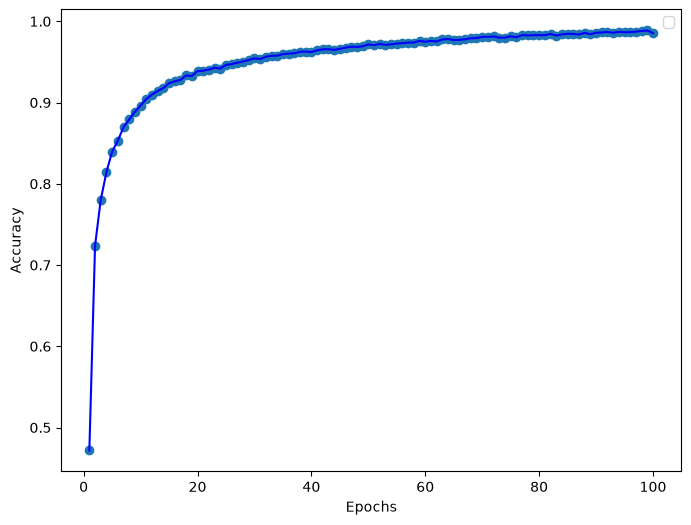

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(range(1,101),accuracy)
plt.plot(range(1,101),accuracy,color='blue')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend()
plt.show()
#training accuracy climbs 99% from 48% 

In [22]:
from sklearn.metrics import accuracy_score, f1_score,precision_score, recall_score, classification_report

In [23]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis = 1)

acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [24]:
print(f"Test Accuracy:  {acc:.4f}")
print(f"Precision (W):  {precision:.4f}")
print(f"Recall (W):     {recall:.4f}")
print(f"F1-Score (W):   {f1:.4f}")

# 4. Optional: Print a detailed classification report per letter (A-Z)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy:  0.9422
Precision (W):  0.9430
Recall (W):     0.9422
F1-Score (W):   0.9423

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       144
           1       0.87      0.89      0.88       156
           2       0.95      0.94      0.95       147
           3       0.91      0.91      0.91       163
           4       0.93      0.96      0.95       144
           5       0.94      0.93      0.94       146
           6       0.92      0.91      0.91       173
           7       0.89      0.93      0.91       133
           8       0.98      0.93      0.95       108
           9       0.95      0.95      0.95       150
          10       0.99      0.93      0.96       149
          11       0.96      0.96      0.96       147
          12       0.99      0.97      0.98       143
          13       0.97      0.96      0.97       138
          14       0.92      0.93      0.93       131
          15       

In [25]:
#change hyperparameter manually 
model2=tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation = 'leaky_relu',input_shape = (X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation = 'leaky_relu'),
    tf.keras.layers.Dense(32, activation = 'leaky_relu'),
    tf.keras.layers.Dense(26, activation = 'softmax'),
])

optimizer = tf.keras.optimizers.Adam(learning_rate = 0.01)

C:\Users\LENOVO\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
model2.compile(
    loss = 'sparse_categorical_crossentropy',
    optimizer = optimizer,
    metrics = ['mae','accuracy']
)

In [ ]:
model2.fit(X_train,y_train, epochs = 100)

Epoch 1/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6940 - loss: 0.9894 - mae: 12.4902
Epoch 2/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8137 - loss: 0.5961 - mae: 12.4902
Epoch 3/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8449 - loss: 0.5003 - mae: 12.4902
Epoch 4/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8542 - loss: 0.4650 - mae: 12.4902
Epoch 5/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8629 - loss: 0.4462 - mae: 12.4902
Epoch 6/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8738 - loss: 0.4177 - mae: 12.4902
Epoch 7/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8820 - loss: 0.3965 - mae: 12.4902
Epoch 8/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8807 - loss: 0.4068 - mae: 12.4902
Epoch 9/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8889 - loss: 0.3767 - mae: 12.4902
Epoch 10/100
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8819 - loss: 0

In [40]:
acc = model2.history.history['accuracy']
print(acc)

mae = model2.history.history['mae']

[0.6939868927001953, 0.8137136697769165, 0.8449176549911499, 0.8541582822799683, 0.8628632426261902, 0.8738449215888977, 0.8820142149925232, 0.8806749582290649, 0.8889111876487732, 0.8819472193717957, 0.8988214731216431, 0.894402027130127, 0.8944690227508545, 0.8933306336402893, 0.9047810435295105, 0.9092004895210266, 0.9013659954071045, 0.9030400514602661, 0.8990223407745361, 0.9080621600151062, 0.9063881039619446, 0.9102718830108643, 0.8994910717010498, 0.9148252606391907, 0.9148921966552734, 0.9096692204475403, 0.9059863686561584, 0.9063211679458618, 0.911745011806488, 0.9168340563774109, 0.9185081124305725, 0.9116110801696777, 0.9199812412261963, 0.9128833413124084, 0.9199812412261963, 0.925271213054657, 0.9104058146476746, 0.9165662527084351, 0.9149591326713562, 0.9276148676872253, 0.9297575950622559, 0.9209856986999512, 0.9183741807937622, 0.9276818037033081, 0.9283514022827148, 0.924668550491333, 0.9154278635978699, 0.9278826713562012, 0.9126824736595154, 0.9295567274093628, 0.9

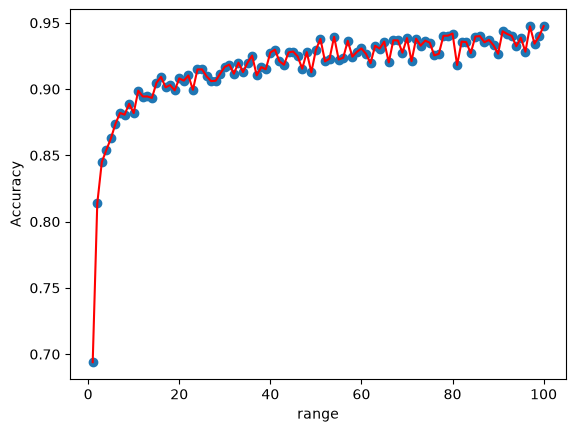

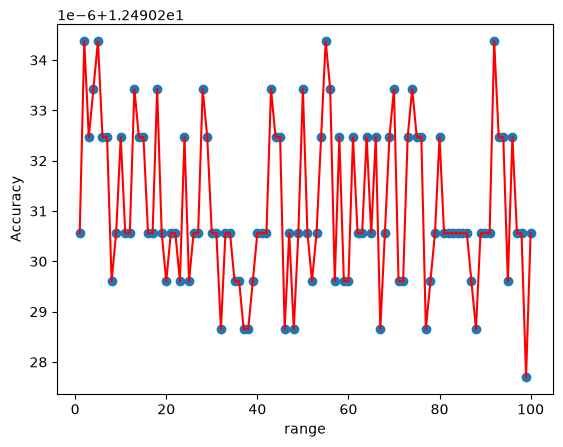

In [41]:
plt.scatter(range(1,101),acc)
plt.plot(range(1,101),acc,color = 'red')
plt.xlabel('range')
plt.ylabel('Accuracy')
plt.show()

plt.scatter(range(1,101),mae)
plt.plot(range(1,101),mae,color = 'red')
plt.xlabel('range')
plt.ylabel('Accuracy')
plt.show()

In [42]:
y_pred_prob = model2.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

ac = accuracy_score(y_test,y_pred)
ps = precision_score(y_test,y_pred, average = 'weighted')
rec = recall_score(y_test,y_pred,average = 'weighted')
f1_s = f1_score(y_test,y_pred,average = 'weighted')

117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [43]:
print(f"Test Accuracy:  {ac:.4f}")
print(f"Precision (W):  {ps:.4f}")
print(f"Recall (W):     {rec:.4f}")
print(f"F1-Score (W):   {f1_s:.4f}")


#when we use relu activation, gives good accuracy then leaky relu accuracy 

Test Accuracy:  0.9250
Precision (W):  0.9284
Recall (W):     0.9250
F1-Score (W):   0.9247


"Switching the hidden layer activation from standard ReLU to Leaky ReLU alongside an increased learning rate of 0.01 resulted in a drop in test accuracy from 93.73% down to 91.81%. This indicates that standard ReLU combined with a more conservative learning rate (0.001) provides a more stable and accurate optimization landscape for this alphabet classification task."

# Hyper parameter Tuning

In [44]:
!pip install keras_tuner 

In [45]:
!pip install tensorboard

In [46]:
import keras_tuner as kt

In [47]:
import tensorboard

In [48]:

def build_model(hp):
    model3 = tf.keras.Sequential()
    model3.add(tf.keras.Input(shape=(X_train.shape[1],)))
    
    # Tune the number of units in the first hidden layer
    hp_units = hp.Choice('units_layer1', values=[32, 64, 128])
    model3.add(tf.keras.layers.Dense(units=hp_units, activation='relu'))
    
    # Tune dropout to prevent overfitting
    if hp.Boolean('use_dropout'):
        model3.add(tf.keras.layers.Dropout(rate=0.2))
        
    # Output layer
    model3.add(tf.keras.layers.Dense(26, activation='softmax'))
    
    # Tune the learning rate for the optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model3.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    return model3  # <--- Make sure this return statement is present!

In [49]:
tuner = kt.RandomSearch(
    build_model,
    objective = 'val_accuracy',
    max_trials = 5,
    executions_per_trial = 1,
    directory = 'alphabet_tuning',
    project_name = 'nn_hyperparameters'
)

tuner.search(
    X_train,y_train,
    epochs = 20,   #fewer epochs per trial 
    validation_data = (X_test, y_test)
)


best_hps = tuner.get_best_hyperparameters(num_trials = 1)[0]
print(f"Optimal unit in layer 1 :{best_hps.get('units_layer1')}")
print(f"Optimal learning rate: {best_hps.get('learning_rate')}")

Reloading Tuner from alphabet_tuning\nn_hyperparameters\tuner0.json
Optimal unit in layer 1 :64
Optimal learning rate: 0.01


In [50]:
# 1. Build the best model using the optimal hyperparameters found by the tuner
model3 = tuner.hypermodel.build(best_hps)

# 2. Train the best model on your training data
model3.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test))

# 3. Generate probability predictions for the test set
y_pred_prob = model3.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

# 4. Calculate metrics (fixed typos in function names)
acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted') # fixed typo from recsll_score
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Test Accuracy: {acc:.4f}")
print(f"Precision (W): {precision:.4f}")
print(f"Recall (W):    {recall:.4f}")
print(f"F1-Score (W):  {f1:.4f}")

Epoch 1/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6551 - loss: 1.1256 - val_accuracy: 0.8091 - val_loss: 0.6380
Epoch 2/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7770 - loss: 0.6920 - val_accuracy: 0.8439 - val_loss: 0.5180
Epoch 3/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8007 - loss: 0.6068 - val_accuracy: 0.8519 - val_loss: 0.4755
Epoch 4/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8158 - loss: 0.5621 - val_accuracy: 0.8755 - val_loss: 0.4150
Epoch 5/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8234 - loss: 0.5292 - val_accuracy: 0.8811 - val_loss: 0.3943
Epoch 6/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8390 - loss: 0.5022 - val_accuracy: 0.8800 - val_loss: 0.3882
Epoch 7/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8412 - loss: 0.4870 - val_accuracy: 0.8803 - val_loss: 0.3902
Epoch 8/20
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8410 - loss: 0.4829 - val_accuracy: 0.

In [52]:
accuracy_hist = model3.history.history['accuracy']

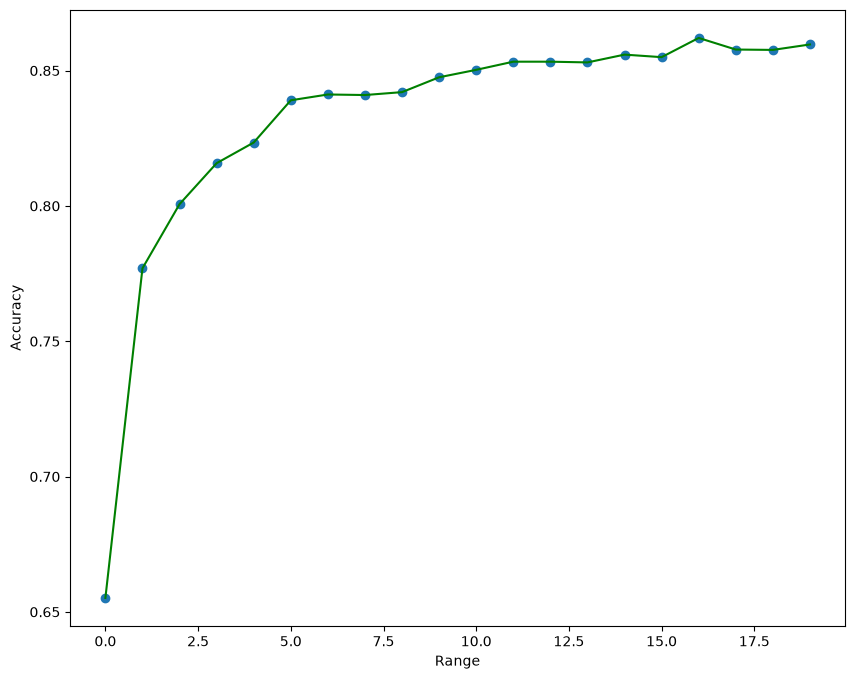

In [53]:
plt.figure(figsize = (10,8))
plt.scatter(range(20),accuracy_hist)
plt.plot(range(20),accuracy_hist, color = 'green')
plt.xlabel('Range')
plt.ylabel('Accuracy')
plt.show()

 # Comparison

#### output feature is categorical type of data, 26 classes in it. we use Softmax activation function for output 
   
    first created 2 hidden layers with 'relu', first 64 neurons and  in second layer  32 neurons and 26 for 'softmax' because we have 26 classes , first model gives good percentage of accuracy (94%)
   
    second we updated parameters manually with 3 hidden layers :-added one more hidden layer (128 neurons), optimizer(learning_rate = 0.01)(default = 0.001), with activation='leaky_relu', model gives less accuracy than 1st model(92%).
    
    third time we did use tuned our  model with 'RandomSearch' with parameters max_trials and accuracy was 90% less than previous model.